<p class="hz-kicker">Week 1 · Live session</p>

# Reading data like a manager

Today you join the management team of Altamar Hotels, three hotels in Chile that set prices and take cancellation risks every single day. By the end of the session you will read the Python a notebook shows you, change it with confidence, and ask your first questions to 6,060 real bookings.

<ul class="hz-lesson-meta"><li>4 hours</li><li>9 ideas</li><li>Runs in your browser</li><li>Case: the question</li></ul>

**Before anything else:** run the cell below. On this site, press its **Run** button (in Google Colab, the ▶ next to it, or Shift + Enter). It loads the tools we use today. You don't need to read it.

In [1]:
# Setup: tools for today. Run this cell first; you don't need to read it.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = "https://raw.githubusercontent.com/hizocar/mba-business-analytics-1/main/docs/datasets/"
pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 120)
print("Ready: the Python tools are loaded.")

Ready: the Python tools are loaded.


## <span class="hz-step-n">01</span> Altamar's two questions

**Altamar Hotels** has three properties: a business hotel in **Santiago**, a beach hotel in **Viña del Mar**, and a lake-and-volcano hotel in **Puerto Varas**. You are now part of its management team, and two questions land on your desk:

- **Revenue management:** *What nightly rate can we charge for a booking?* The industry calls it the **ADR**, average daily rate.
- **Operations:** *Which bookings will cancel, and how many rooms can we safely oversell?*

Neither question is answered once a year. Rates are set every morning for every hotel and room type; overbooking limits are set for every night. Small, daily decisions: exactly where data pays off.

**Why data, and not only experience?** Altamar already has the answer key for thousands of past bookings: the rate each guest paid and whether they cancelled. A good revenue manager carries a feel for these patterns in their head. Data lets you check that feel, find the patterns nobody noticed, and apply them to every booking, every day, consistently.

That is what **machine learning** does, and it fits in one picture.

**Machine learning in one picture.** A model studies past bookings whose answer is known, learns a *recipe* from the inputs to the answer, and applies it to new bookings.

| Hotel | Days ahead | Channel | Nights | | Rate (USD) | Cancelled? |
|---|--:|---|--:|:-:|--:|:-:|
| Viña del Mar | 92 | Online agency | 3 | → | 202.58 | yes |
| Santiago | 5 | Online agency | 2 | → | 115.22 | yes |
| *… 6,058 more …* | | | | | | |
| Puerto Varas | 30 | Direct | 4 | → | **?** | **?** |

Left: the **inputs**, known when the guest books. Right: what we want to **predict**.

The two question marks are two different kinds of prediction:

| | **Regression** | **Classification** |
|---|---|---|
| The answer is | a number | a category, often yes or no |
| Altamar asks | *What rate can we charge?* (column `adr`) | *Will this booking cancel?* (column `canceled`) |
| Other examples | room-nights sold next month, revenue per guest | will this guest come back? is this review a complaint? |
| In this module | weeks 3, 5 and 6 | weeks 4, 5 and 6 |

The first question to ask of any business problem: **is the answer a number or a category?**

<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "The general manager asks: <em>“How many room-nights will Puerto Varas sell next July?”</em> What kind of question is this for a model?", "options": ["Regression: the answer is a number", "Classification: the answer is yes or no", "Neither: a model cannot learn this from past bookings"], "answer": 0, "why": "The answer is a quantity (room-nights), so it is a regression question, just like predicting the rate. “Will this booking cancel?” would be classification.", "code": false}</script>
</div>

## <span class="hz-step-n">02</span> What a notebook is

You are reading a **notebook**: a page that mixes **text cells** (like this one) with **code cells** you can run. Each code cell has a run button; its result appears right under it.

A code cell is a calculator that remembers. The next one describes one booking and computes its revenue. Lines that start with `#` are notes for humans: Python ignores them. Run it.

In [2]:
# One booking at Santiago
adr = 120.5          # the nightly rate, in USD
nights = 3           # length of the stay
print("This stay brings", adr * nights, "USD")

This stay brings 361.5 USD


Python now **remembers** `adr` and `nights`, so any later cell can use them. That memory (the **kernel**) only knows what has already run, **in the order it ran**. Run cells out of order, run one twice, or delete one, and the memory no longer matches what you read on screen.

Play with it: run the three cells below in different orders, run cell 2 twice, delete cell 1 and restart.

<div class="hz-widget" data-widget="notebook-state">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_1_Live/">open this session on the course website</a> to use it.</p>
</div>

**Business takeaway:** a notebook is a report that other people will rerun. Before you share one (or hand in your case), use **Restart and run all**: in Colab, *Runtime → Restart session and run all*; on this site, **Run all**. If it runs top to bottom without errors, your team and your grader see exactly what you saw.

<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "Cell 1 says <code>adr = 120.5</code>. Cell 2 says <code>adr = adr + 10</code>. You run cell 1, then cell 2 <strong>twice</strong>, then <code>print(adr)</code>. What appears?", "options": ["120.5", "130.5", "140.5", "An error"], "answer": 2, "why": "Memory keeps results, not cells: cell 2 added 10 twice, so adr is 140.5. Restart and run all would give 130.5, the number the code on screen suggests.", "code": false}</script>
</div>

## <span class="hz-step-n">03</span> Reading Python: values and names

You don't need to write Python from scratch, but you need to **read** it. Almost every line you will see does one of three things: it gives a **name** to a **value**, it combines values, or it shows a result.

`adr = 180.5` reads *“let `adr` be 180.5”*. The `=` is not an equation; it attaches a label to a value. Values come in a few **types**: numbers (with or without decimals), text, and yes/no. Step through a booking below.

<div class="hz-widget" data-widget="variables">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_1_Live/">open this session on the course website</a> to use it.</p>
</div>

The same booking, as a code cell. `type()` tells you what kind of value a name holds: `str` is text, `float` a number with decimals, `int` a whole number, `bool` yes/no.

To turn values into a sentence, Python uses **f-strings**: an `f` before the quotes, and any name inside `{ }` is replaced by its value. `{revenue:,.2f}` means *two decimals and a thousands comma*. F-strings are how a notebook talks to a manager.

In [3]:
hotel = "Viña del Mar"     # text (str): always in quotes
adr = 180.5                # number with decimals (float): USD per night
nights = 3                 # whole number (int)
parking = True             # yes/no (bool): True or False, no quotes

print(type(hotel), type(adr), type(nights), type(parking))

revenue = adr * nights
print(f"A {nights}-night stay at {hotel} at USD {adr} a night brings USD {revenue:,.2f}.")

<class 'str'> <class 'float'> <class 'int'> <class 'bool'>
A 3-night stay at Viña del Mar at USD 180.5 a night brings USD 541.50.


✏️ **Your turn.** Cells marked ✏️ have settings at the top, in CAPITALS. Change them, run the cell again, and read the new sentence. Try a long stay at Puerto Varas, or a one-night stay in Santiago.

In [4]:
# ✏️ Change these settings
HOTEL = "Puerto Varas"
ADR = 210.0
NIGHTS = 5

print(f"{NIGHTS} nights at {HOTEL}, USD {ADR} a night: USD {ADR * NIGHTS:,.2f} of room revenue.")

5 nights at Puerto Varas, USD 210.0 a night: USD 1,050.00 of room revenue.


**Watch out: numbers that are really text.** Numbers often arrive from a file or a web form as text, in quotes. Python will not do arithmetic with text; it stops with an error message. Errors are normal and informative: read the last line, it says what went wrong. Here we catch the error so the notebook keeps running, then fix it with `float()`.

In [5]:
rate_from_form = "180.5"          # text, not a number: note the quotes
try:
    print(rate_from_form + 20)
except TypeError as error:
    print("Python refuses:", error)

print("After float():", float(rate_from_form) + 20)

Python refuses: can only concatenate str (not "int") to str
After float(): 200.5


## <span class="hz-step-n">04</span> Collections: lists and dictionaries

One booking is a handful of values. A business has many, so Python groups them.

A **list** keeps values **in order**, inside square brackets: for example, Santiago's rates for the next five nights. You reach an item by its **position**, and positions start at **0**: `rates[0]` is the first night, `rates[-1]` the last. Try the expressions below.

<div class="hz-widget" data-widget="list-index" data-name='rates' data-items='[95.0, 120.5, 88.0, 142.0, 110.0]' data-noun='rate' data-presets='["rates[0]", "rates[2]", "rates[-1]", "rates[1:3]", "rates[:3]", "rates[5]"]' data-start='rates[0]'>
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_1_Live/">open this session on the course website</a> to use it.</p>
</div>

Lists are useful because Python can summarize them in one word: `len` counts, `sum` adds, `max` finds the highest.

In [6]:
rates = [95.0, 120.5, 88.0, 142.0, 110.0]     # Santiago, next five nights, USD

print("First night:", rates[0], "| last night:", rates[-1])
print(f"{len(rates)} nights, total USD {sum(rates):,.2f}, highest USD {max(rates)}")
print(f"Average rate: USD {sum(rates) / len(rates):.2f}")

First night: 95.0 | last night: 110.0
5 nights, total USD 555.50, highest USD 142.0
Average rate: USD 111.10


A **dictionary** stores values under **names** instead of positions, inside curly braces. It is the natural shape of **one record**: one booking, with its hotel, channel, rate… You ask for `booking["hotel"]`, not for “item number 2”. Asking for a name that is not there is an error; `.get()` asks politely and accepts a fallback.

<div class="hz-widget" data-widget="dict-lookup">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_1_Live/">open this session on the course website</a> to use it.</p>
</div>

Here is that booking in code. It is a real one: the first row of Altamar's file, which you will meet again in block 2.

In [7]:
booking = {
    "booking_id": "AH-200974",
    "hotel": "Viña del Mar",
    "channel": "Online travel agency",
    "lead_time_days": 92,
    "nights": 3,
    "adr": 202.58,
    "canceled": True,
}
print(booking["hotel"], "|", booking["nights"], "nights at USD", booking["adr"])
print("Country:", booking.get("country", "not recorded"))

Viña del Mar | 3 nights at USD 202.58
Country: not recorded


Now the key step: **a list of dictionaries is a table**. Each dictionary is a row; each name is a column. The `pandas` library turns it into a **DataFrame**, a spreadsheet-like table. Altamar's booking file is exactly this, with 6,060 rows and 20 columns.

In [8]:
few_bookings = [
    {"hotel": "Santiago", "nights": 2, "adr": 115.22, "canceled": True},
    {"hotel": "Viña del Mar", "nights": 3, "adr": 202.58, "canceled": True},
    {"hotel": "Puerto Varas", "nights": 5, "adr": 148.0, "canceled": False},
    {"hotel": "Santiago", "nights": 1, "adr": 98.5, "canceled": False},
]
tiny = pd.DataFrame(few_bookings)
tiny

,hotel,nights,adr,canceled
0,Santiago,2,115.22,True
1,Viña del Mar,3,202.58,True
2,Puerto Varas,5,148.00,False
3,Santiago,1,98.50,False


## <span class="hz-step-n">05</span> Rules and functions

Managers work with **rules of thumb**. Operations at Altamar has one: *“bookings made more than 90 days ahead through an online travel agency are high cancellation risk.”* In Python a rule is an `if`: a test that is either `True` or `False`, followed by what to do in each case. `elif` (“else if”) adds a second test, `else` catches everything left.

Change the booking below and follow the dot through the rule.

<div class="hz-widget" data-widget="if-flow">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_1_Live/">open this session on the course website</a> to use it.</p>
</div>

The same rule as a code cell. Three details to read in it: `==` **compares** (while `=` assigns), `and` needs both tests, `or` needs one. And the **indentation** (the spaces at the start of a line) says which lines belong to each branch.

In [9]:
# ✏️ Change these settings
CHANNEL = "Online travel agency"     # or "Direct", "Corporate", "Travel agent"
LEAD_TIME_DAYS = 120

if CHANNEL == "Online travel agency" and LEAD_TIME_DAYS > 90:
    risk = "high"
elif CHANNEL == "Online travel agency" or LEAD_TIME_DAYS > 90:
    risk = "watch"
else:
    risk = "low"
print(f"Booked via {CHANNEL}, {LEAD_TIME_DAYS} days ahead: cancellation risk {risk}.")

Booked via Online travel agency, 120 days ahead: cancellation risk high.


A **function** packages a calculation so you can reuse it for any booking: write it once, call it a thousand times. `def` starts it, the names in brackets are its **inputs**, and `return` sends back its **output**. An input with `=` has a **default**: if you don't pass it, Python uses that value.

Change the inputs and watch Altamar's revenue function work.

<div class="hz-widget" data-widget="function-machine">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_1_Live/">open this session on the course website</a> to use it.</p>
</div>

The function in code. Read it top to bottom: full price first, then the discount if there is one, then round to cents. The two `print` lines call it twice, without and with a 10% discount.

In [10]:
def stay_revenue(adr, nights, discount=0):
    """Room revenue of one stay, after an optional discount (0.10 = 10% off)."""
    total = adr * nights
    if discount > 0:
        total = total * (1 - discount)
    return round(total, 2)

print(stay_revenue(180.5, 3))
print(stay_revenue(180.5, 3, discount=0.10))

541.5
487.35


✏️ **Predict, then run.** Before you press run, write down the revenue you expect. A long-stay discount of 12% on a 7-night stay at USD 150: is it more or less than USD 1,000?

In [11]:
# ✏️ Change these settings, predict the result, then run
ADR = 150.0
NIGHTS = 7
DISCOUNT = 0.12      # a long-stay discount of 12%

revenue = stay_revenue(ADR, NIGHTS, DISCOUNT)
print(f"{NIGHTS} nights at USD {ADR} with {DISCOUNT:.0%} off: USD {revenue:,.2f}")

7 nights at USD 150.0 with 12% off: USD 924.00


<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "What does <code>stay_revenue(100.0, 4, discount=0.25)</code> return?", "options": ["400.0", "300.0", "375.0", "100.0"], "answer": 1, "why": "Full price is 100 × 4 = 400. A discount of 0.25 keeps 75% of it: 400 × 0.75 = 300.0.", "code": true}</script>
</div>

## ☕ Break

Ten minutes. When we come back: the real data. Everything so far was one booking at a time; Altamar has thousands.

## <span class="hz-step-n">06</span> Doing it for thousands of bookings

The rule and the function above work on **one** booking. To apply them to 6,060 bookings, you could write a **loop**: *for each booking, do this*. It works, but it is slow and long to read.

The libraries **NumPy** and **pandas** do it differently: you write the operation once, for the **whole column**, and they apply it to every row at once. Race the two below.

<div class="hz-widget" data-widget="vectorize">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_1_Live/">open this session on the course website</a> to use it.</p>
</div>

Both ways in code, on six rates. The loop needs three lines and visits each booking; the array version is one line. Same result.

In [12]:
rates_list = [95.0, 120.5, 88.0, 142.0, 110.0, 185.0]

new_rates = []                          # the loop way: one booking at a time
for r in rates_list:
    new_rates.append(round(r * 1.08, 2))
print("Loop: ", new_rates)

rates = np.array(rates_list)            # the array way: the whole column at once
print("Array:", (rates * 1.08).round(2))

Loop:  [102.6, 130.14, 95.04, 153.36, 118.8, 199.8]
Array: [102.6  130.14  95.04 153.36 118.8  199.8 ]


**Business takeaway:** from now on, almost every line of code works on a whole column. `df["adr"] * 1.08` raises every rate in the file by 8%; `df["adr"].mean()` averages all of them. One line, any number of bookings. You will rarely see a loop again in this module.

## <span class="hz-step-n">07</span> Meet the data

Altamar's booking system exported every booking with arrival in 2024 or 2025: one row per booking. `pd.read_csv` reads the file into a DataFrame we call `df` (short for *data frame*). `.shape` gives its size: rows, columns.

In [13]:
df = pd.read_csv(DATA + "altamar_bookings.csv")
rows, columns = df.shape
print(f"{rows:,} bookings and {columns} columns")

6,060 bookings and 20 columns


`.head()` shows the first five rows. Look for the booking you met in idea 4 (`AH-200974`) and read its row from left to right.

In [14]:
df.head()

,booking_id,hotel,booking_date,arrival_date,lead_time_days,nights,weekend_nights,adults,children,room_type,customer_type,channel,deposit,repeat_guest,previous_cancellations,special_requests,parking,country,adr,canceled
0,AH-200974,Viña del Mar,2023-10-15,2024-01-15,92,3,0,2,2.0,Superior,Leisure,Online travel agency,Non-refundable,0,0,2,0,Other,202.58,1
1,AH-204908,Santiago,2024-10-11,2024-10-16,5,2,0,1,0.0,Standard,Business,Online travel agency,No deposit,0,1,1,0,Chile,115.22,1
2,AH-202738,Viña del Mar,2024-07-31,2024-08-13,13,5,2,2,0.0,Standard,Leisure,Direct,Non-refundable,0,0,2,0,Chile,68.57,0
3,AH-205156,Viña del Mar,2024-02-18,2024-03-15,26,6,3,2,0.0,Superior,Leisure,Online travel agency,No deposit,0,0,2,1,Chile,133.13,0
4,AH-200450,Puerto Varas,2025-02-26,2025-04-08,41,3,0,2,2.0,Standard,Leisure,Direct,No deposit,0,0,2,0,NaN,113.35,0


**The columns, in business terms (1/2): the booking and the stay.**

| Column | What it tells a manager |
|---|---|
| `booking_id` | the booking's reference number |
| `hotel` | Santiago, Viña del Mar or Puerto Varas |
| `booking_date`, `arrival_date` | when the guest booked, when they arrive |
| `lead_time_days` | days between the two: how far ahead they booked |
| `nights`, `weekend_nights` | length of stay, and how many are Friday or Saturday |
| `adults`, `children` | guests in the room |
| `room_type` | Standard, Superior or Suite |

**The columns (2/2): the guest, the channel, and the two answers.**

| Column | What it tells a manager |
|---|---|
| `customer_type` | Business, Leisure or Group |
| `channel` | Direct, Online travel agency, Corporate, Travel agent |
| `deposit` | No deposit or Non-refundable |
| `repeat_guest`, `previous_cancellations` | loyalty, and past behaviour (1 = yes) |
| `special_requests`, `parking`, `country` | extras asked for, and where the guest is from |
| **`adr`** | rate paid per night, USD: **the revenue question** |
| **`canceled`** | 1 if the booking was cancelled: **the operations question** |

Full dictionary: [Datasets](https://hizocar.github.io/mba-business-analytics-1/datasets/datasets/).

`.describe()` summarizes every numeric column in one table: how many values (`count`), the average (`mean`), the spread (`std`), the smallest and largest (`min`, `max`), and the quartiles (`25%`, `50%` = the median, `75%`). We turn it sideways (`.T`) so each column of the data is one line.

In [15]:
df.describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
lead_time_days,6060.0,48.8,54.2,-152.0,11.0,30.0,67.0,424.0
nights,6060.0,3.9,2.1,1.0,2.0,3.0,6.0,8.0
weekend_nights,6060.0,1.7,1.2,0.0,1.0,2.0,3.0,4.0
adults,6060.0,1.9,0.8,0.0,1.0,2.0,2.0,4.0
children,5999.0,0.4,0.8,0.0,0.0,0.0,0.0,3.0
repeat_guest,6060.0,0.1,0.3,0.0,0.0,0.0,0.0,1.0
previous_cancellations,6060.0,0.2,0.5,0.0,0.0,0.0,0.0,3.0
special_requests,6060.0,0.7,0.9,0.0,0.0,0.0,1.0,6.0
parking,6060.0,0.3,0.5,0.0,0.0,0.0,1.0,1.0
adr,6060.0,128.2,66.6,0.0,87.8,113.4,155.2,1668.1


**Read it like a manager: what is surprising?**

- **`lead_time_days` min is −152.** A booking made 152 days *after* arrival is impossible: dates were swapped somewhere.
- **`adr` min is 0.0.** Free rooms exist (staff, complimentary stays), but they are not prices; they would drag every average down.
- **`adr` max is 1,668.1**, while 75% of bookings pay at most 155.2. An extra zero typed by hand?
- **`adults` min is 0**: a room booked for nobody.
- **`children` count is 5,999**, not 6,060: some values are missing.

None of this is unusual. Real data is dirty; finding it is the first job.

One line per surprise. `df["adr"] == 0` asks the question **for every row** and gives a yes/no column; `.sum()` counts the yeses.

In [16]:
print("Negative lead times:   ", (df["lead_time_days"] < 0).sum())
print("Rate of 0:             ", (df["adr"] == 0).sum())
print("Rate above USD 1,000:  ", (df["adr"] > 1000).sum())
print("Bookings for 0 adults: ", (df["adults"] == 0).sum())
print("Missing children value:", df["children"].isna().sum())

Negative lead times:    10
Rate of 0:              12
Rate above USD 1,000:   6
Bookings for 0 adults:  8
Missing children value: 61


<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "The <code>describe()</code> line for <code>adr</code> reads: count 6,060 · mean 128.2 · 50% 113.4 · max 1,668.1. What is the best reading?", "options": ["A typical booking pays around USD 113 a night; the maximum looks like an error worth checking", "Most bookings pay around USD 1,668 a night", "Exactly half the bookings pay more than USD 128.2", "There are 6,060 different rates in the file"], "answer": 0, "why": "The median (50%) says half the bookings pay less than USD 113.4. The mean is higher because a few very large values pull it up, like the 1,668 that is probably a typo. Count is the number of rows with a value, not of different rates.", "code": false}</script>
</div>

## <span class="hz-step-n">08</span> First questions to the data

Now the questions a manager would ask on day one, one line each. First: **how many bookings does each hotel have?** `value_counts()` counts how often each label appears. Look at the bottom of the list.

In [17]:
df["hotel"].value_counts()

hotel
Santiago        2378
Viña del Mar    1987
Puerto Varas    1439
SANTIAGO         110
Pto. Varas        74
VIÑA DEL MAR      37
Vina del Mar      35
Name: count, dtype: int64

A chart makes the problem impossible to miss.

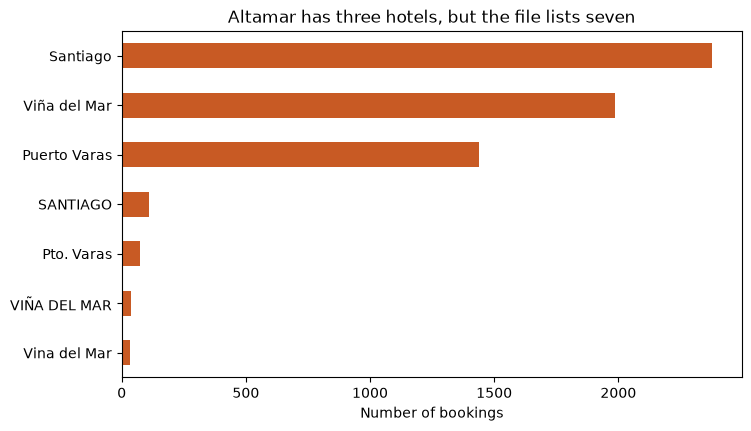

In [18]:
counts = df["hotel"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
counts.plot.barh(ax=ax, color="#c85a24")
ax.set_title("Altamar has three hotels, but the file lists seven")
ax.set_xlabel("Number of bookings")
ax.set_ylabel("")
plt.show()

**Three hotels, seven labels.** `SANTIAGO`, `Vina del Mar`, `VIÑA DEL MAR` and `Pto. Varas` are the same hotels typed differently by different systems. To Python, a different spelling is a different hotel, so 256 bookings are counted apart from their hotel. Fixing that is week 2's first job; for today, keep it in mind when you read the next numbers.

Next question: **what is the average rate in each hotel?** `groupby("hotel")` splits the table by hotel; `["adr"].mean()` averages the rate in each group.

In [19]:
df.groupby("hotel")["adr"].mean().round(1).sort_values(ascending=False)

hotel
Puerto Varas    158.0
Pto. Varas      148.5
Viña del Mar    140.4
VIÑA DEL MAR    138.3
Vina del Mar    137.4
SANTIAGO        101.9
Santiago        100.3
Name: adr, dtype: float64

Last question: **how often do bookings cancel?** `canceled` is 1 for a cancelled booking and 0 otherwise, so its **average is the share cancelled**. `:.1%` prints it as a percentage. Then the same `groupby` pattern gives it by hotel.

In [20]:
overall = df["canceled"].mean()
print(f"{overall:.1%} of all bookings were cancelled: about 1 in {1 / overall:.0f}.")
print("By hotel, % cancelled:")
by_hotel = df.groupby("hotel")["canceled"].mean().sort_values(ascending=False)
print((by_hotel * 100).round(1).to_string())

33.7% of all bookings were cancelled: about 1 in 3.
By hotel, % cancelled:
hotel
VIÑA DEL MAR    51.4
Vina del Mar    48.6
Viña del Mar    40.9
Puerto Varas    37.5
Pto. Varas      35.1
Santiago        25.7
SANTIAGO        17.3


**What a manager takes from this:**

- **One booking in three is cancelled.** That is the room inventory operations has to protect with overbooking.
- **Viña del Mar cancels most** (about 41% under its main label) and **Santiago least** (about 26%). One overbooking policy for the whole group would be wrong for both.
- **Puerto Varas charges the highest average rate** (about USD 158), Santiago the lowest (about USD 100).
- **But every number above is slightly off**: split labels, free rooms and typos are all inside these averages. Week 2 cleans the data first, then repeats these questions.

## <span class="hz-step-n">09</span> Case clinic: the question

Your [applied case](https://hizocar.github.io/mba-business-analytics-1/case/case/) advances with the sessions. This week's step: **the question**. With your team:

1. **Form your team** (3 or 4 people) and **choose a case**: A · TalentCo (what drives a salary: regression), B · FinTrust Bank (who will not repay: classification), or C · your own data.
2. **Write the business question in two lines**, and **who would use the answer**, for which decision.
3. **Open the [case toolkit](https://hizocar.github.io/mba-business-analytics-1/case/Case_Toolkit/) in Colab** (button at the top of the page; see the [Colab guide](https://hizocar.github.io/mba-business-analytics-1/colab/)), choose your dataset in section **00 Settings**, and run section **01 Load and first look**: a first look at your data, like ours at Altamar.

**An example, written for Altamar.** Notice it names a decision and a person, not a technique.

> **Question:** Which bookings are likely to cancel, so that each hotel can decide how many rooms to oversell every night?
>
> **Who uses the answer:** the operations manager of each hotel, every morning, when setting the overbooking limit.
>
> **Column to predict:** `canceled` (yes/no → classification).

A weak version would be *“analyse cancellations with machine learning”*: no decision, no user, nothing to check at the end.

✏️ **Your team's version** (in Colab, double-click this cell to edit it):

> **Question:** …
>
> **Who uses the answer, for which decision:** …
>
> **Column to predict:** … (a number → regression; a category → classification)
>
> **One thing we noticed in the first look at the data:** …

**Before next week:** do the lab, [First look at Altamar](https://hizocar.github.io/mba-business-analytics-1/sessions/Session_1_Lab/), and its graded quiz. In week 2, [From raw data to insight](https://hizocar.github.io/mba-business-analytics-1/sessions/Session_2_Live/), we fix the seven hotel labels, the free rooms and the typos, and we find out that every hotel has its own seasons.